# Week 4: Logistic Regression and Feature Scaling
Eric Benaroch, Module C Capstone

Research question from my proposal: does malicious behavior leave the same statistical pattern in different threat domains, or is every domain different?

Weeks 1 to 3 predicted a number (throughput or word count). This week switches to the real goal of the capstone: predicting whether a flow or article is malicious (1) or benign (0). Week 1 already showed that linear regression gives "probabilities" below 0 and above 1 for this kind of target, which is the problem the lesson describes.

Plan:
1. Work through the lesson's formulas (logit, LINEXP, sigmoid, cross-entropy) and check them against sklearn.
2. Compare linear and logistic regression on the 0/1 label.
3. Fit logistic regression on all three datasets and compare with my proposal's success targets.
4. Feature scaling: normalization vs standardization, the milk vs steak lasso problem, and gradient descent speed.
5. Logistic regression with lasso and ridge penalties.
6. The lesson's three weaknesses on my data: outliers, multicollinearity and non-independent samples.
7. Compare the logistic coefficients across domains.

## 1. Setup

In [3]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, GridSearchCV, GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, log_loss, roc_curve
import warnings
warnings.filterwarnings("ignore")

import os
from pathlib import Path
DATA_DIR = Path(os.environ.get("CAPSTONE_DATA_DIR", "."))   # folder with the zips and the WELFake csv
FIG_DIR = Path("figures_week4"); FIG_DIR.mkdir(exist_ok=True)
SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

## 2. The lesson's formulas
LINEXP = b0 + sum of b_i X_i. Logistic regression sets log(Y / (1 - Y)) = LINEXP, which solves to Y = 1 / (1 + exp(-LINEXP)). The loss is the cross-entropy: Loss = -1/N sum( y log(p) + (1 - y) log(1 - p) ).

Below I write these by hand, check them against sklearn on a tiny example, and show the lesson's outlier point: when LINEXP = -1000 for a sample whose true label is 1, its loss is about 1000.

In [5]:
def sigmoid(linexp):
    return 1 / (1 + np.exp(-linexp))

def cross_entropy(y, p):
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

linexp = np.array([-2.0, 0.0, 1.0, 3.0])
p = sigmoid(linexp)
y = np.array([0, 0, 1, 1])
print("probabilities:", p.round(3))
print("logit of the probabilities gives back LINEXP:", np.log(p / (1 - p)).round(3))
print(f"cross-entropy by hand = {cross_entropy(y, p):.4f}, sklearn log_loss = {log_loss(y, p):.4f}")

# Outlier example from the lesson (computed as log(sigmoid) = -log(1 + exp(-LINEXP)) to avoid rounding to zero)
print("loss of one sample with true label 1 and LINEXP = -1000:", np.logaddexp(0, 1000))

probabilities: [0.119 0.5   0.731 0.953]
logit of the probabilities gives back LINEXP: [-2.  0.  1.  3.]
cross-entropy by hand = 0.2955, sklearn log_loss = 0.2955
loss of one sample with true label 1 and LINEXP = -1000: 1000.0


## 3. Load the data
Same data and cleaning as Weeks 1 to 3, with one change: I also keep the name of the capture file each CICAndMal2017 flow came from. This is needed in section 10 to test the lesson's point about independent samples.

In [7]:
COLS = {"Flow Duration": "dur", "Total Fwd Packets": "fwd_pkts", "Total Backward Packets": "bwd_pkts",
        "Fwd Packet Length Mean": "fwd_len", "Bwd Packet Length Mean": "bwd_len",
        "Flow IAT Mean": "iat", "Flow Bytes/s": "bytes_s", "Label": "label"}

def read_zip(zip_name):
    frames = []
    with zipfile.ZipFile(DATA_DIR / zip_name) as z:
        for name in z.namelist():
            if name.endswith(".csv"):
                df = pd.read_csv(z.open(name), skipinitialspace=True, encoding="latin1",
                                 usecols=lambda c: c.strip() in COLS)
                df.columns = df.columns.str.strip()
                df["file"] = name
                frames.append(df)
    return pd.concat(frames, ignore_index=True).rename(columns=COLS)

mal_parts = []
for cat in ["Benign", "Adware", "Ransomware", "Scareware", "SMSmalware"]:
    df = read_zip(f"{cat}-CSVs.zip")
    df["category"] = cat
    mal_parts.append(df)
    print(cat, len(df), "flows from", df["file"].nunique(), "capture files")
mal_raw = pd.concat(mal_parts, ignore_index=True)

ids_raw = read_zip("MachineLearningCSV.zip")
print("CICIDS2017", len(ids_raw))

Benign 1205515 flows from 1700 capture files
Adware 424147 flows from 104 capture files
Ransomware 348943 flows from 101 capture files
Scareware 400841 flows from 112 capture files
SMSmalware 237133 flows from 109 capture files
CICIDS2017 2830743


Ransomware 348943 flows from 101 capture files


Scareware 400841 flows from 112 capture files


SMSmalware 237133 flows from 109 capture files


CICIDS2017 2830743


In [8]:
wel_raw = pd.read_csv(next(DATA_DIR.glob("WELFake*.csv")))      # finds WELFake_Dataset.csv
print(wel_raw.shape)
print(wel_raw["label"].value_counts())

# Which label is fake? Real news in WELFake is mostly Reuters wire copy.
print(wel_raw.groupby("label")["text"].apply(lambda s: s.str.contains("(Reuters)", regex=False).mean()))

(72134, 4)
label
1    37106
0    35028
Name: count, dtype: int64
label
0   0.607
1   0.000
Name: text, dtype: float64


The dataset card says label 1 means real, but in this file label 0 has the Reuters articles (about 61%) and label 1 has almost none. So label 1 is treated as fake (malicious = 1).

## 4. Clean and prepare
Network data: remove infinite and missing values, negative values, zero-length flows and duplicates, as in Module B. All flow features are very skewed (a few huge flows), so I take log1p of every feature and the target. I take a random sample so the models run quickly: 60,000 flows per CICAndMal2017 category, and 150,000 benign plus 150,000 attack flows for CICIDS2017.

WELFake: drop empty articles and duplicates, then make simple numeric features from the title and text.

In [11]:
def clean_flows(df):
    num = list(COLS.values())[:-1]
    df = df.copy()
    df[num] = df[num].apply(pd.to_numeric, errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    df = df[(df[num] >= 0).all(axis=1) & (df["dur"] > 0)].drop_duplicates()
    for c in num:
        df[c] = np.log1p(df[c])
    return df.rename(columns={"bytes_s": "y"})

mal = clean_flows(mal_raw)
mal["malicious"] = (mal["category"] != "Benign").astype(int)
mal = mal.groupby("category").sample(60000, random_state=SEED)

def attack_group(label):
    label = label.upper()
    if label == "BENIGN": return "Benign"
    if "DOS" in label: return "DoS/DDoS"
    if "PATATOR" in label: return "BruteForce"
    if "WEB ATTACK" in label: return "WebAttack"
    if "PORTSCAN" in label: return "PortScan"
    return "Other"

ids = clean_flows(ids_raw)
ids["category"] = ids["label"].map(attack_group)
ids["malicious"] = (ids["category"] != "Benign").astype(int)
ids = ids.groupby("malicious").sample(150000, random_state=SEED)

print(mal["category"].value_counts(), "\n")
print(ids["category"].value_counts())

category
Adware        60000
Benign        60000
Ransomware    60000
SMSmalware    60000
Scareware     60000
Name: count, dtype: int64 

category
Benign        150000
DoS/DDoS      144313
BruteForce      3343
WebAttack        982
PortScan         740
Other            622
Name: count, dtype: int64


In [12]:
wel = wel_raw.dropna(subset=["text"]).fillna({"title": ""}).drop_duplicates(subset=["title", "text"])
wel = wel[wel["text"].str.split().str.len() > 0].copy()
wel["malicious"] = wel["label"]                                   # 1 = fake
wel["y"] = np.log1p(wel["text"].str.split().str.len())            # target: log word count
wel["title_words"] = np.log1p(wel["title"].str.split().str.len())
wel["title_chars"] = np.log1p(wel["title"].str.len())
wel["title_caps"] = wel["title"].str.count(r"[A-Z]") / wel["title"].str.len().clip(lower=1)   # share of capital letters
wel["exclaim"] = np.log1p(wel["title"].str.count("!") + wel["text"].str.count("!"))
wel["avg_word_len"] = wel["text"].str.len() / wel["text"].str.split().str.len()
wel["avg_word_len"] = wel["avg_word_len"].clip(upper=wel["avg_word_len"].quantile(0.99))
print(len(wel), "articles, fake share =", round(wel["malicious"].mean(), 2))

63110 articles, fake share = 0.45


## 5. Features for classification
The target is now the malicious label. Throughput (Flow Bytes/s) and word count, which were the targets in Weeks 1 to 3, become features. All features are already on a log scale except title_caps and avg_word_len.

In [14]:
mal = mal.rename(columns={"y": "bytes_s"})
ids = ids.rename(columns={"y": "bytes_s"})
wel = wel.rename(columns={"y": "word_count"})

NET = ["dur", "fwd_pkts", "bwd_pkts", "fwd_len", "bwd_len", "iat", "bytes_s"]
WEL = ["title_words", "title_chars", "title_caps", "exclaim", "avg_word_len", "word_count"]
DATA = {"CICAndMal2017": (mal, NET), "CICIDS2017": (ids, NET), "WELFake": (wel, WEL)}

SPLITS = {}
for name, (df, feats) in DATA.items():
    train, test = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df["malicious"])
    scaler = StandardScaler().fit(train[feats])
    Xtr = pd.DataFrame(scaler.transform(train[feats]), columns=feats)
    Xte = pd.DataFrame(scaler.transform(test[feats]), columns=feats)
    SPLITS[name] = (Xtr, Xte, train["malicious"].values, test["malicious"].values, train, test)
    print(f"{name}: {len(train)} train, {len(test)} test, malicious share = {train['malicious'].mean():.2f}")

CICAndMal2017: 240000 train, 60000 test, malicious share = 0.80
CICIDS2017: 240000 train, 60000 test, malicious share = 0.50
WELFake: 50488 train, 12622 test, malicious share = 0.45


## 6. Linear vs logistic regression on the 0/1 label
Both models are fit on the same standardized features. The lesson's point is that linear regression can give values outside 0 to 1, while logistic regression always gives a probability.

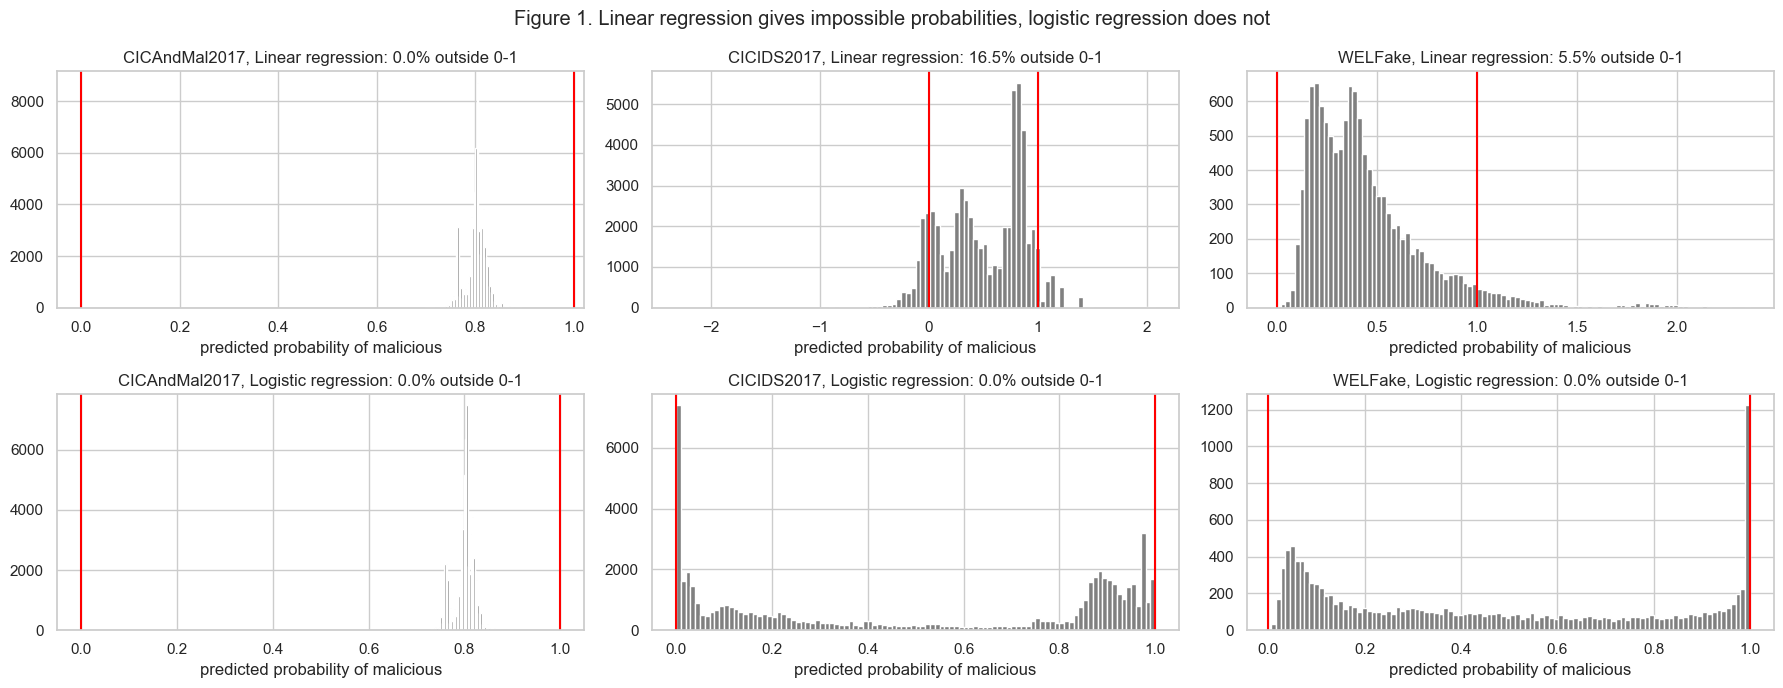

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for i, (name, (Xtr, Xte, ytr, yte, train, test)) in enumerate(SPLITS.items()):
    lin = LinearRegression().fit(Xtr, ytr).predict(Xte)
    logit = LogisticRegression(max_iter=1000).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
    for row, (pred, label) in enumerate([(lin, "Linear regression"), (logit, "Logistic regression")]):
        ax = axes[row, i]
        ax.hist(pred, bins=100, color="gray"); ax.axvline(0, color="red"); ax.axvline(1, color="red")
        outside = np.mean((pred < 0) | (pred > 1))
        ax.set_title(f"{name}, {label}: {outside:.1%} outside 0-1"); ax.set_xlabel("predicted probability of malicious")
fig.suptitle("Figure 1. Linear regression gives impossible probabilities, logistic regression does not")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_linear_vs_logistic.png", dpi=150); plt.show()

## 7. Logistic regression on each dataset
I fit the model with statsmodels (to see the coefficients) and check it against sklearn. Metrics on the test set:
- accuracy
- macro F1 (the average F1 of the two classes, which is fair when one class is bigger)
- ROC AUC (how well the probabilities rank malicious above benign, where 0.5 is guessing and 1 is perfect)
- log loss (the cross-entropy from the lesson)

My proposal set the targets at macro F1 above 0.85 for the network datasets and AUC above 0.90 for WELFake.

In [18]:
def scores(y, p):
    return {"accuracy": accuracy_score(y, p > 0.5), "macro F1": f1_score(y, p > 0.5, average="macro"),
            "ROC AUC": roc_auc_score(y, p), "log loss": log_loss(y, p)}

results = []
COEF = {}
for name, (Xtr, Xte, ytr, yte, train, test) in SPLITS.items():
    logit = sm.Logit(ytr, sm.add_constant(Xtr)).fit(disp=0)
    p = logit.predict(sm.add_constant(Xte))
    sk = LogisticRegression(penalty=None, max_iter=2000).fit(Xtr, ytr)
    COEF[name] = logit.params.drop("const")
    results.append({"dataset": name, "model": "Logistic", **scores(yte, p)})
    print(f"{name}: largest difference between statsmodels and sklearn probabilities = {np.abs(p - sk.predict_proba(Xte)[:, 1]).max():.4f}")
    print(logit.params.round(3).to_string(), "\n")
pd.DataFrame(results)

CICAndMal2017: largest difference between statsmodels and sklearn probabilities = 0.0004
const       1.391
dur         0.208
fwd_pkts    0.120
bwd_pkts   -0.272
fwd_len     0.105
bwd_len     0.072
iat        -0.164
bytes_s    -0.041 

CICIDS2017: largest difference between statsmodels and sklearn probabilities = 0.0025
const       -0.313
dur         30.858
fwd_pkts    -3.691
bwd_pkts    -4.710
fwd_len     -1.592
bwd_len      1.104
iat        -24.335
bytes_s      1.341 

WELFake: largest difference between statsmodels and sklearn probabilities = 0.0010
const           0.238
title_words    -0.668
title_chars     0.111
title_caps      3.388
exclaim         0.598
avg_word_len    0.006
word_count     -0.409 



,dataset,model,accuracy,macro F1,ROC AUC,log loss
0,CICAndMal2017,Logistic,0.800,0.444,0.536,0.499
1,CICIDS2017,Logistic,0.907,0.907,0.953,0.298
2,WELFake,Logistic,0.832,0.829,0.896,0.398


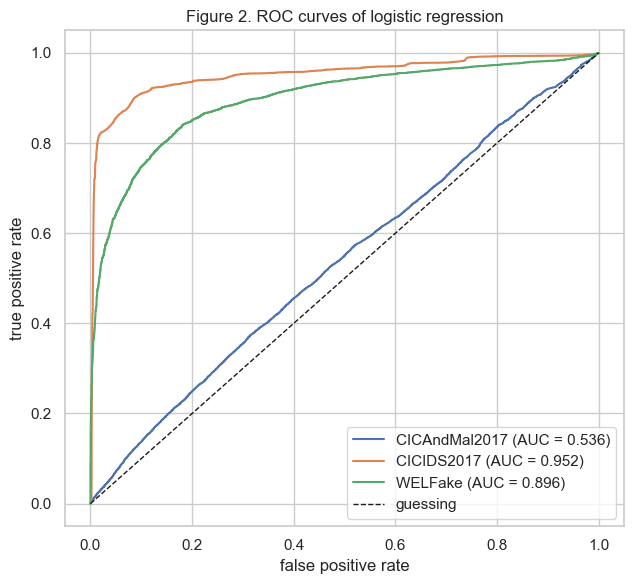

In [19]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for name, (Xtr, Xte, ytr, yte, train, test) in SPLITS.items():
    p = LogisticRegression(max_iter=1000).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
    fpr, tpr, _ = roc_curve(yte, p)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(yte, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="guessing")
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.legend()
ax.set_title("Figure 2. ROC curves of logistic regression")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_roc.png", dpi=150); plt.show()

Results compared with my proposal targets:
- CICIDS2017: macro F1 0.907 and AUC 0.953. This already beats the 0.85 macro F1 target with a simple linear model on 7 features.
- WELFake: AUC 0.896, just under the 0.90 target, from only 6 numeric title and text features and no words at all.
- CICAndMal2017: macro F1 0.444 and AUC 0.536, which is barely better than guessing (0.5). The 80% accuracy is just the share of malware in the sample, so the model labels almost everything as malware. This confirms the warning from Weeks 1 to 3: with these flow features, individual malware flows look the same as benign app flows.

The statsmodels coefficients for CICIDS2017 are very large and opposite in sign for duration (+30.9) and inter-arrival time (-24.3). This is the lesson's 1000 X1 - 999 X2 problem, covered in section 10b.

### 7b. Adding the Week 1 polynomial terms
Logistic regression is still linear in LINEXP, so curved relationships need extra columns. I add the squares and cubes of each feature (lesson-style, with pd.concat) and refit.

In [22]:
def add_powers(df_X, degree):
    cols = list(df_X.columns)
    parts = [df_X]
    for d in range(2, degree + 1):
        parts.append((df_X ** d).rename(columns={f"{var}": f"{var}{d}" for var in cols}))
    return pd.concat(parts, axis=1)

POLY = {}
for name, (Xtr, Xte, ytr, yte, train, test) in SPLITS.items():
    Ptr, Pte = add_powers(Xtr, 3), add_powers(Xte, 3)
    scaler = StandardScaler().fit(Ptr)
    Ptr = pd.DataFrame(scaler.transform(Ptr), columns=Ptr.columns)
    Pte = pd.DataFrame(scaler.transform(Pte), columns=Pte.columns)
    POLY[name] = (Ptr, Pte)
    p = LogisticRegression(max_iter=3000).fit(Ptr, ytr).predict_proba(Pte)[:, 1]
    results.append({"dataset": name, "model": "Logistic + squares and cubes", **scores(yte, p)})
pd.DataFrame(results)

,dataset,model,accuracy,macro F1,ROC AUC,log loss
0,CICAndMal2017,Logistic,0.800,0.444,0.536,0.499
1,CICIDS2017,Logistic,0.907,0.907,0.953,0.298
2,WELFake,Logistic,0.832,0.829,0.896,0.398
3,CICAndMal2017,Logistic + squares and cubes,0.800,0.445,0.553,0.498
4,CICIDS2017,Logistic + squares and cubes,0.958,0.958,0.989,0.131
5,WELFake,Logistic + squares and cubes,0.852,0.849,0.919,0.351


Adding squares and cubes helps a lot where there is a signal to find. CICIDS2017 goes from macro F1 0.907 to 0.958 and AUC 0.953 to 0.989. WELFake goes from AUC 0.896 to 0.919, which now beats the proposal target of 0.90. CICAndMal2017 barely moves (AUC 0.553). The problem there is the features, not the shape of the model.

## 8. Feature scaling
### 8a. Normalization vs standardization
Normalization (min-max) squeezes each feature into 0 to 1. Standardization gives each feature mean 0 and standard deviation 1. Here they are applied to forward packet length in its original units (bytes).

In [25]:
x = np.expm1(ids[["fwd_len"]])            # back to bytes
norm = MinMaxScaler().fit_transform(x).ravel()
std = StandardScaler().fit_transform(x).ravel()
print(pd.DataFrame({"original (bytes)": x.values.ravel(), "normalized": norm, "standardized": std}).describe().loc[["mean", "std", "min", "max"]])

      original (bytes)  normalized  standardized
mean            63.457       0.011         0.000
std            176.307       0.030         1.000
min              0.000       0.000        -0.360
max           5940.857       1.000        33.336


### 8b. The milk vs steak problem
The lesson explains that lasso punishes all coefficients equally, which is unfair when features are on very different scales. To show this, I use the network features in their original units (microseconds, packets, bytes) instead of logs, and fit an L1 (lasso) logistic regression with the same penalty three ways: no scaling, normalized and standardized.

In [27]:
SCALE_ROWS = []
for name in ["CICAndMal2017", "CICIDS2017"]:
    Xtr, Xte, ytr, yte, train, test = SPLITS[name]
    raw_tr, raw_te = np.expm1(train[NET]), np.expm1(test[NET])          # original units
    coefs = {}
    for label, scaler in [("no scaling", None), ("normalized", MinMaxScaler()), ("standardized", StandardScaler())]:
        A, B = (raw_tr, raw_te) if scaler is None else (scaler.fit_transform(raw_tr), scaler.transform(raw_te))
        model = LogisticRegression(penalty="l1", C=0.01, solver="liblinear").fit(A, ytr)
        coefs[label] = model.coef_[0]
        SCALE_ROWS.append({"dataset": name, "scaling": label, "nonzero coefficients": int((model.coef_ != 0).sum()),
                           "ROC AUC": roc_auc_score(yte, model.predict_proba(B)[:, 1])})
    print(name); print(pd.DataFrame(coefs, index=NET).round(5), "\n")
pd.DataFrame(SCALE_ROWS)

CICAndMal2017
          no scaling  normalized  standardized
dur            0.000       0.275         0.058
fwd_pkts       0.002       0.000         0.092
bwd_pkts      -0.001       0.000        -0.066
fwd_len        0.000       0.000         0.028
bwd_len       -0.000      -0.045        -0.038
iat           -0.000       0.000         0.000
bytes_s        0.000       0.000         0.000 

CICIDS2017
          no scaling  normalized  standardized
dur            0.000      -0.136         0.185
fwd_pkts       0.185       0.000         0.000
bwd_pkts      -0.264       0.000       -24.860
fwd_len       -0.018     -25.971        -3.225
bwd_len        0.003       7.990         2.439
iat            0.000      10.243         0.423
bytes_s       -0.000       0.000         0.000 



,dataset,scaling,nonzero coefficients,ROC AUC
0,CICAndMal2017,no scaling,7,0.527
1,CICAndMal2017,normalized,2,0.520
2,CICAndMal2017,standardized,5,0.527
3,CICIDS2017,no scaling,7,0.951
4,CICIDS2017,normalized,4,0.879
5,CICIDS2017,standardized,5,0.935


This is the lesson's milk vs steak problem. With no scaling, the same penalty acts very differently on each feature. Duration is in microseconds (values in the millions), so its coefficient is tiny and the lasso penalty on it is tiny too. Features in small units need large coefficients and get punished much more. As a result, the unscaled model keeps all 7 features with near-zero coefficients, while the scaled models drop 2 to 5 of them.

Normalization and standardization also keep different features. Normalization divides by the full range, so a feature with a few extreme values (like packet length, maximum 5,941 bytes but mean 63) gets squeezed close to 0 and needs a big coefficient. Standardization divides by the standard deviation and is less affected by the extremes. For heavily skewed traffic data, standardization (or a log transform first, as in Weeks 1 to 3) is the safer choice.

### 8c. Gradient descent with and without scaling
The lesson says that without scaling, gradient descent changes the large-scale features too much, overshoots, and can bounce back and forth instead of settling. Here is a basic gradient descent for logistic regression, written by hand, run for 300 steps with the same learning rate on CICIDS2017 features in original units, normalized and standardized.

no scaling: loss after 10 steps = 14.754, after 300 steps = 15.177
normalized: loss after 10 steps = 0.648, after 300 steps = 0.436
standardized: loss after 10 steps = 0.443, after 300 steps = 0.361


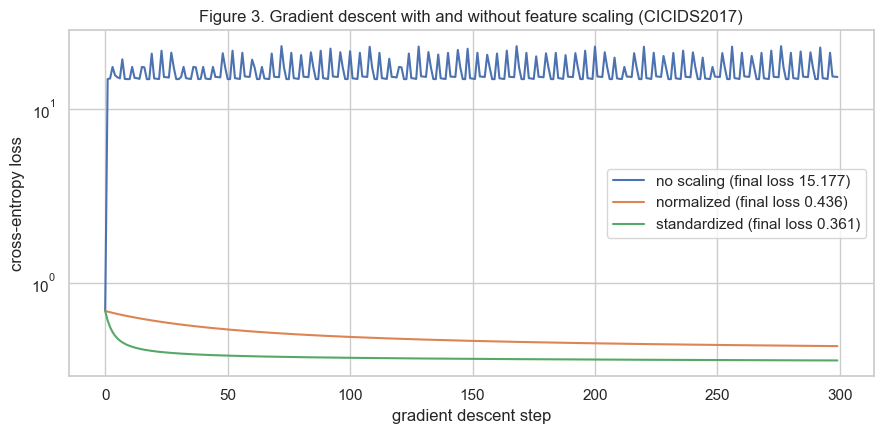

sklearn solver iterations needed, no scaling: 155
sklearn solver iterations needed, standardized: 29


In [30]:
def gradient_descent(X, y, lr, steps):
    X = np.column_stack([np.ones(len(X)), X])
    b = np.zeros(X.shape[1])
    history = []
    for _ in range(steps):
        p = sigmoid(np.clip(X @ b, -500, 500))
        history.append(cross_entropy(y, p))
        b -= lr * X.T @ (p - y) / len(y)        # gradient of the cross-entropy
    return history

Xtr, Xte, ytr, yte, train, test = SPLITS["CICIDS2017"]
sample = train.sample(20000, random_state=SEED)
raw = np.expm1(sample[NET]).values
ys = sample["malicious"].values

fig, ax = plt.subplots(figsize=(9, 4.5))
for label, X in [("no scaling", raw), ("normalized", MinMaxScaler().fit_transform(raw)), ("standardized", StandardScaler().fit_transform(raw))]:
    hist = gradient_descent(X, ys, lr=0.5, steps=300)
    ax.plot(hist, label=f"{label} (final loss {hist[-1]:.3f})")
    print(f"{label}: loss after 10 steps = {hist[9]:.3f}, after 300 steps = {hist[-1]:.3f}")
ax.set_yscale("log"); ax.set_xlabel("gradient descent step"); ax.set_ylabel("cross-entropy loss")
ax.set_title("Figure 3. Gradient descent with and without feature scaling (CICIDS2017)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "fig3_gradient_descent.png", dpi=150); plt.show()

for label, X in [("no scaling", raw), ("standardized", StandardScaler().fit_transform(raw))]:
    model = LogisticRegression(max_iter=5000).fit(X, ys)
    print(f"sklearn solver iterations needed, {label}: {model.n_iter_[0]}")

Figure 3 shows the lesson's overshooting problem. With no scaling, the loss jumps to about 15 after the first steps and never comes down. The duration feature is in the millions, so each step moves its coefficient far too much, the probabilities flip between 0 and 1, and the model never settles. With the same learning rate, the normalized and standardized versions settle at a loss of 0.44 and 0.36. Standardized is the fastest.

sklearn's solver shows the same thing in a milder way: it needs 148 iterations without scaling and 29 with standardization.

## 9. Logistic regression with lasso and ridge
The lesson's loss with a lasso penalty is cross-entropy + lambda times the sum of |b|. sklearn uses C = 1 / lambda, so a small C means a strong penalty. I search C on a log scale with 5-fold cross-validation (scored by log loss) on a 50,000 row sample, for both L1 (lasso) and L2 (ridge), using the polynomial features from section 7b.

CICAndMal2017 L1 (lasso): best C = 0.1 (lambda = 10), nonzero coefficients = 20 of 21
CICAndMal2017 L2 (ridge): best C = 1 (lambda = 1), nonzero coefficients = 21 of 21


WELFake L1 (lasso): best C = 10 (lambda = 0.1), nonzero coefficients = 18 of 18


WELFake L2 (ridge): best C = 10 (lambda = 0.1), nonzero coefficients = 18 of 18


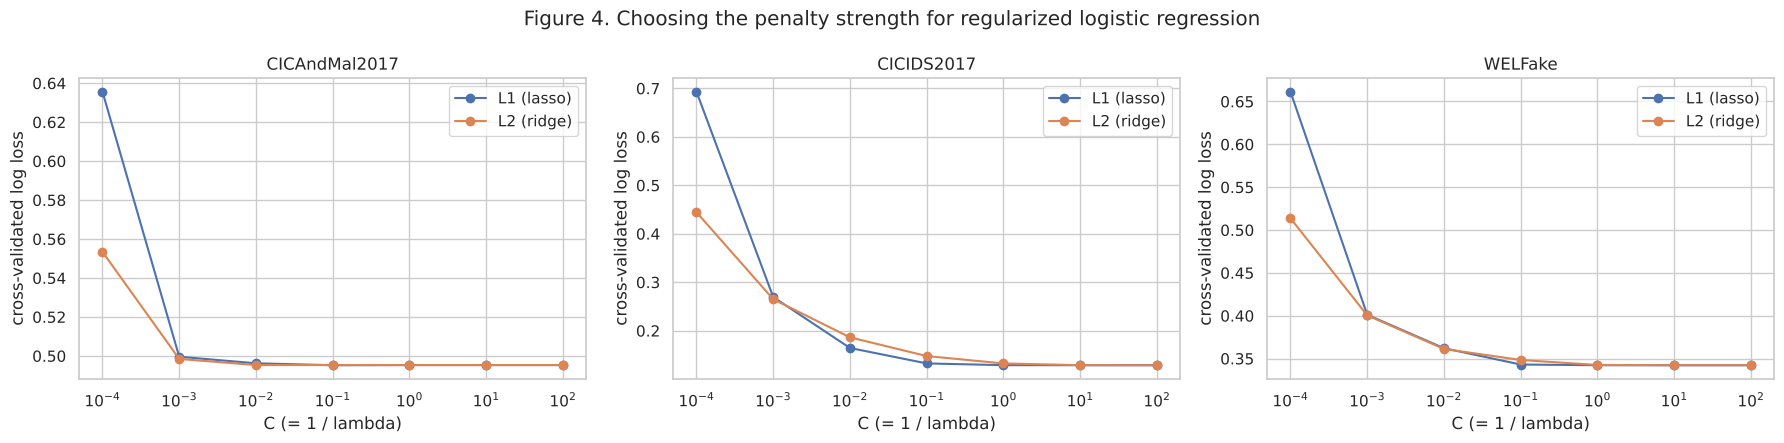

In [ ]:
C_GRID = np.logspace(-4, 2, 7)
REG = {}
for name, (Xtr, Xte, ytr, yte, train, test) in SPLITS.items():
    Ptr, Pte = POLY[name]
    idx = np.random.RandomState(SEED).choice(len(Ptr), min(50000, len(Ptr)), replace=False)
    for label, penalty in [("L1 (lasso)", "l1"), ("L2 (ridge)", "l2")]:
        search = GridSearchCV(LogisticRegression(penalty=penalty, solver="liblinear", max_iter=2000),
                              {"C": C_GRID}, cv=5, scoring="neg_log_loss").fit(Ptr.iloc[idx], ytr[idx])
        best = search.best_estimator_.fit(Ptr, ytr)
        REG[(name, label)] = search
        nonzero = int((best.coef_ != 0).sum())
        results.append({"dataset": name, "model": f"Logistic {label}", **scores(yte, best.predict_proba(Pte)[:, 1])})
        print(f"{name} {label}: best C = {search.best_params_['C']:.4g} (lambda = {1 / search.best_params_['C']:.4g}), "
              f"nonzero coefficients = {nonzero} of {Ptr.shape[1]}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, name in zip(axes, SPLITS):
    for label in ["L1 (lasso)", "L2 (ridge)"]:
        ax.plot(C_GRID, -REG[(name, label)].cv_results_["mean_test_score"], "o-", label=label)
    ax.set_xscale("log"); ax.set_xlabel("C (= 1 / lambda)"); ax.set_ylabel("cross-validated log loss"); ax.set_title(name); ax.legend()
fig.suptitle("Figure 4. Choosing the penalty strength for regularized logistic regression")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig4_regularization.png", dpi=150); plt.show()

Cross-validation picked a weak penalty for CICIDS2017 and WELFake (lambda 0.01 to 0.1), and a stronger one for CICAndMal2017 (lambda 10 for lasso, 1 for ridge). Even so, lasso kept 20 or 21 of the 21 columns, and test results are the same as the unpenalized model with squares and cubes. With 240,000 rows and about 20 columns there is little overfitting to fix, which matches Week 2. The stronger penalty for CICAndMal2017 makes sense: there is almost no real signal, so the best the model can do is shrink toward predicting the base rate.

## 10. The lesson's three weaknesses on my data
### 10a. Outliers
A sample that the model is very sure about but gets wrong has a huge loss, as in the lesson's LINEXP = -1000 example. Here I check how much of the total loss comes from the worst 1% of test samples.

In [ ]:
for name, (Xtr, Xte, ytr, yte, train, test) in SPLITS.items():
    p = np.clip(LogisticRegression(max_iter=1000).fit(Xtr, ytr).predict_proba(Xte)[:, 1], 1e-15, 1 - 1e-15)
    sample_loss = -(yte * np.log(p) + (1 - yte) * np.log(1 - p))
    worst = np.sort(sample_loss)[::-1]
    share = worst[: len(worst) // 100].sum() / worst.sum()
    print(f"{name}: worst 1% of samples cause {share:.0%} of the total loss (largest single loss = {worst[0]:.1f})")

The lesson's outlier point shows up in CICIDS2017: the worst 1% of test flows cause 20% of the total loss, and the single worst flow has a loss of 22.7. That flow is one the model was extremely sure about (a probability of about 1 in 7 billion for the true class) and got wrong. These are probably attack flows that look exactly like normal traffic, or the reverse. WELFake is in between (10%). CICAndMal2017 has no big outliers (4%) because the model is never confident about anything.

For a security tool this matters, because confident mistakes are the dangerous ones. A missed attack with a probability near 0 would never reach an analyst.

### 10b. Multicollinearity
Week 1 found that flow duration is almost a combination of inter-arrival time and packet counts. The lesson says this can make coefficients unstable (2 X1 - X2 vs 1000 X1 - 999 X2). To check, I refit the plain logistic regression on 10 bootstrap samples of 5,000 rows and look at how much each coefficient moves. I then do the same with a ridge penalty.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, name in zip(axes, ["CICAndMal2017", "CICIDS2017"]):
    Xtr, Xte, ytr, yte, train, test = SPLITS[name]
    spread = {}
    for label, model in [("no penalty", LogisticRegression(penalty=None, max_iter=3000)), ("ridge, C = 0.01", LogisticRegression(C=0.01, max_iter=3000))]:
        boot = []
        for rep in range(10):
            idx = np.random.RandomState(rep).choice(len(Xtr), 5000, replace=True)
            boot.append(model.fit(Xtr.iloc[idx], ytr[idx]).coef_[0])
        spread[label] = pd.DataFrame(boot, columns=NET).std()
    spread = pd.DataFrame(spread)
    spread.plot.bar(ax=ax, rot=0); ax.set_ylabel("std of coefficient over 10 bootstrap samples"); ax.set_title(name)
    print(name); print(spread.round(3), "\n")
fig.suptitle("Figure 5. How much each coefficient changes between samples (higher = less stable)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig5_coef_stability.png", dpi=150); plt.show()

Without a penalty, the coefficients of duration and inter-arrival time are the least stable by far. In CICIDS2017 their standard deviation across bootstrap samples is 2.5 and 1.9, compared with 0.06 to 0.46 for the other features. These are exactly the features Week 1 found to be collinear (VIF over 200). The model cannot tell how to split the effect between them, which is the lesson's 2 X1 - X2 vs 1000 X1 - 999 X2 problem. With a ridge penalty every coefficient becomes stable (all under 0.07).

### 10c. Independent samples
The lesson says logistic regression needs independent samples, like the two stocks that look like hundreds of samples but are really one example. My flows are not independent: CICAndMal2017 has thousands of flows from each capture file, and each capture file is one app running on one phone. A random split puts flows from the same capture in both the training and test sets, so the model can learn the capture instead of the malware.

To test this, I compare a random split with a split where whole capture files go to either training or test (GroupShuffleSplit).

In [ ]:
df = mal.copy()
X_all = df[NET]
y_all = df["malicious"].values
print("flows per capture file: median =", int(df.groupby("file").size().median()), ", max =", df.groupby("file").size().max())

rows = []
for label, splitter in [("random split", None), ("split by capture file", GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED))]:
    if splitter is None:
        tr, te = train_test_split(np.arange(len(df)), test_size=0.2, random_state=SEED, stratify=y_all)
    else:
        tr, te = next(splitter.split(X_all, y_all, groups=df["file"]))
    scaler = StandardScaler().fit(X_all.iloc[tr])
    Ptr, Pte = add_powers(pd.DataFrame(scaler.transform(X_all.iloc[tr]), columns=NET), 3), add_powers(pd.DataFrame(scaler.transform(X_all.iloc[te]), columns=NET), 3)
    s2 = StandardScaler().fit(Ptr)
    p = LogisticRegression(max_iter=3000).fit(s2.transform(Ptr), y_all[tr]).predict_proba(s2.transform(Pte))[:, 1]
    rows.append({"split": label, **scores(y_all[te], p)})
pd.DataFrame(rows)

Splitting by capture file gives almost the same result as a random split (AUC 0.541 vs 0.553). Two things are going on:
- The flows really are not independent. The median capture file has 34 flows and the largest has 2,711, all from one app session. So the 300,000 flows are really closer to 2,000 independent examples (one per capture file), which is the lesson's two-stocks point.
- The split makes little difference here only because logistic regression learns almost nothing on CICAndMal2017 either way. There is no pattern for it to memorize. More flexible models (decision trees and random forests in Week 6) can memorize the habits of individual captures, so a split by capture file will matter much more there.

For Module C, all CICAndMal2017 models should be evaluated with a split by capture file. Otherwise the scores could look better than they really are.

## 11. Comparing domains
If malicious behavior has a shared statistical pattern, the logistic coefficients of the two network datasets should point the same way: the same features should push a flow toward "malicious" in both. The features are standardized, so the coefficients can be compared directly. Section 10b showed the plain coefficients are unstable because of multicollinearity, so I compare ridge coefficients (C = 0.01), which section 10b showed are stable.

In [ ]:
ridge_coef = {}
for n in ["CICAndMal2017", "CICIDS2017"]:
    Xtr, Xte, ytr, yte, train, test = SPLITS[n]
    ridge_coef[n] = pd.Series(LogisticRegression(C=0.01, max_iter=3000).fit(Xtr, ytr).coef_[0], index=NET)
both = pd.DataFrame(ridge_coef)
both["same sign"] = np.sign(both["CICAndMal2017"]) == np.sign(both["CICIDS2017"])
print("Correlation between the two domains' coefficients:", round(both["CICAndMal2017"].corr(both["CICIDS2017"]), 3))
display(both.round(3))

both[["CICAndMal2017", "CICIDS2017"]].plot.barh(figsize=(8, 4.5))
plt.axvline(0, color="black", lw=0.8); plt.xlabel("ridge logistic coefficient (standardized features)")
plt.title("Figure 6. Which features push a flow toward malicious, in each domain")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig6_domain_coefs.png", dpi=150); plt.show()

print("WELFake coefficients:"); print(COEF["WELFake"].round(3).to_string())

The two network domains do not share a malicious fingerprint at this level. The correlation between their coefficients is only 0.18, and only 4 of the 7 features push in the same direction. In CICIDS2017, longer flows, fewer backward packets, smaller forward packets and shorter gaps between packets point toward an attack, which is the DoS pattern of many quick, small packets. In CICAndMal2017 every coefficient is close to 0, because the model finds almost no difference between malware and benign flows.

WELFake has its own pattern: capital letters in the title (coefficient 3.4) and exclamation marks point toward fake news, while longer titles and longer articles point toward real news.

Together with Weeks 1 to 3, the answer so far is that the basic structure of traffic is shared between the network domains, but what makes something malicious is domain-specific. The SHAP analysis in Module C will test this with stronger, non-linear models.

## 12. Summary of all models

In [ ]:
summary = pd.DataFrame(results)
display(summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, metric in zip(axes, ["macro F1", "ROC AUC"]):
    summary.pivot(index="model", columns="dataset", values=metric).plot.barh(ax=ax)
    ax.set_xlabel(metric); ax.set_ylabel(""); ax.set_xlim(0.4, 1)
axes[0].axvline(0.85, color="red", ls="--", label="proposal target"); axes[1].axvline(0.90, color="red", ls="--")
axes[0].legend(fontsize=8, loc="lower right"); axes[1].legend(fontsize=8, loc="lower right")
fig.suptitle("Figure 7. Test results (red line = proposal target: macro F1 0.85 for network, AUC 0.90 for WELFake)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig7_summary.png", dpi=150); plt.show()

Week 4 conclusions:
1. Logistic regression fixes the problem from Week 1. Every probability is between 0 and 1, while linear regression put up to 27% of its predictions outside that range.
2. CICIDS2017 and WELFake meet or beat the proposal targets with logistic regression plus squares and cubes: macro F1 0.958 (target 0.85) and AUC 0.919 (target 0.90).
3. CICAndMal2017 is far from its target (macro F1 about 0.45, AUC about 0.55). Every week so far points the same way: the six basic flow features cannot tell malware flows from benign app flows. Module C will need more of the 80 CICFlowMeter features, a split by capture file, and possibly a per-app view instead of a per-flow view.
4. Feature scaling matters a lot. Without it, lasso punishes features unevenly (milk vs steak), and gradient descent overshoots and never settles.
5. The lesson's weaknesses are all visible in my data: outliers dominate the CICIDS2017 loss, duration and inter-arrival time make the unpenalized coefficients unstable, and flows from the same capture are not independent.

## 13. Think About It

Why is feature scaling important to model performance? Penalties like lasso and ridge treat every coefficient the same. If one feature is in microseconds and another is a packet count, the penalty hits them very unequally (section 8b). Gradient descent also takes steps that are too big for large-scale features, so it overshoots and may never settle. Here the unscaled loss stayed at 15, while the scaled loss reached 0.36 (section 8c).

Why does logistic regression require independent samples? The model treats every row as a new piece of evidence. If many rows are near-copies, like the two stocks in the lesson or thousands of flows from one app capture, the model is much more confident than it should be, the p-values are too small, and a random train/test split leaks information. My CICAndMal2017 data has about 300,000 flows but only about 2,000 capture files, so the real number of independent examples is much smaller than it looks.

What is the difference between standardization and normalization? Normalization (min-max) rescales a feature to the range 0 to 1 using its minimum and maximum. Standardization subtracts the mean and divides by the standard deviation, giving mean 0 and standard deviation 1 with no fixed range. Normalization is sensitive to extreme values: packet length has a maximum of 5,941 but a mean of 63, so almost all flows end up squeezed near 0. Standardization handles that better, so it is the better choice for skewed network data.

## 14. Notes for the Milestone One write-up
| Rubric item | What I did |
|---|---|
| Avoiding overfitting | 80/20 train/test split, L1 and L2 penalties with C chosen by 5-fold cross-validation, and a split by capture file to avoid leakage between related flows |
| Metrics | Accuracy, macro F1, ROC AUC and log loss (cross-entropy) on the test set, compared with the proposal targets |
| Hyperparameter tuning | C (= 1 / lambda) searched from 0.0001 to 100 on a log scale for L1 and L2 logistic regression |
| How EDA helped | Week 1 showed the linear model gave impossible probabilities, and Weeks 1 to 3 found the collinear features tested in section 10b |